# Model 14: Partial NULL Decipherment

## Hypothesis
Model 13 (nucleus-only) demonstrated that stripping onset/coda glyphs improves
statistical metrics (100% n-gram, 95.8% R-hat) but produces words too short (~2.2 chars)
for meaningful Hebrew. The full mapping (Model 7, neural v2) gives correct word lengths
but suffers from |Σ|/|A| = 6.1 dominance.

**Key insight:** Not all onset/coda glyphs are equally structural. Some appear in their
dominant position 100% of the time (purely structural), while others appear 60-70%
(partially inshapetive). A **parameterized threshold θ** controls which glyphs are NULL:

- θ = 1.0 (strict): only glyphs with 100% position-locking are NULL → near-full mapping
- θ = 0.5 (aggressive): glyphs with >50% locking are NULL → near nucleus-only
- **Sweet spot:** θ such that decoded word length ≈ 3.5–4.0 Hebrew chars

This model sweeps θ ∈ {0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00} to find the optimal
balance between reducing |Σ|/|A| and maintaining adequate word length.

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import requests
from scipy.spatial.distance import jensenshannon
warnings.filterwarnings('ignore')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cuda


In [2]:
# ── Cell 2: Parse Voynich + TP-P20 segmentation + positional classification ──

def parse_sta(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', line):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', line)
            if not match:
                continue
            text = match.group(1).strip()
            text = re.sub(r'\{[^}]*\}', '', text)
            text = re.sub(r'<[^>]*>', '', text)
            text = re.sub(r'-', '.', text)
            for w in text.split('.'):
                w = w.strip()
                if not w:
                    continue
                glyphs = re.findall(r'[A-Z][0-9a-z]', w)
                if glyphs:
                    tokens.extend(glyphs)
                    tokens.append('.')
    return tokens


def tokens_to_words(tokens):
    words, current = [], []
    for t in tokens:
        if t == '.':
            if current:
                words.append(current)
                current = []
        else:
            current.append(t)
    if current:
        words.append(current)
    return words


def build_transition_matrix(words):
    all_glyphs = sorted({g for w in words for g in w})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M = np.zeros((n, n))
    for word in words:
        for i in range(len(word) - 1):
            M[index[word[i]], index[word[i+1]]] += 1
    row_sums = M.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    return M / row_sums, all_glyphs, index


def segment_tp(words, M_prob, index, percentile=20):
    all_tp = []
    for word in words:
        for i in range(len(word) - 1):
            g1, g2 = word[i], word[i+1]
            if g1 in index and g2 in index:
                all_tp.append(M_prob[index[g1], index[g2]])
    threshold = np.percentile(all_tp, percentile)
    result = []
    for word in words:
        if not word:
            continue
        syls = []
        cur = [word[0]]
        for i in range(len(word) - 1):
            p = M_prob[index[word[i]], index[word[i+1]]] if (word[i] in index and word[i+1] in index) else 0.0
            if p < threshold:
                syls.append(cur)
                cur = [word[i+1]]
            else:
                cur.append(word[i+1])
        syls.append(cur)
        result.append(syls)
    return result, threshold


def classify_positions(words_as_syls):
    """Classify each glyph occurrence as onset/nucleus/coda based on syllable position."""
    glyph_pos_counts = defaultdict(lambda: Counter())
    for word_syls in words_as_syls:
        for syl in word_syls:
            n = len(syl)
            if n == 1:
                glyph_pos_counts[syl[0]]['nucleus'] += 1
            elif n == 2:
                glyph_pos_counts[syl[0]]['onset'] += 1
                glyph_pos_counts[syl[1]]['coda'] += 1
            else:
                glyph_pos_counts[syl[0]]['onset'] += 1
                for g in syl[1:-1]:
                    glyph_pos_counts[g]['nucleus'] += 1
                glyph_pos_counts[syl[-1]]['coda'] += 1
    return glyph_pos_counts


def compute_glyph_info(glyph_pos_counts, min_freq=5):
    """For each glyph: dominant position and position-locking fraction."""
    glyph_info = {}
    for g, counts in glyph_pos_counts.items():
        total = sum(counts.values())
        if total < min_freq:
            glyph_info[g] = {'dominant': '?', 'pct_dominant': 0.0, 'total': total}
            continue
        pct = {pos: counts[pos] / total for pos in ['onset', 'nucleus', 'coda']}
        dominant = max(pct, key=pct.get)
        glyph_info[g] = {
            'dominant': dominant,
            'pct_dominant': pct[dominant],
            'pct_onset': pct['onset'],
            'pct_nucleus': pct['nucleus'],
            'pct_coda': pct['coda'],
            'total': total,
        }
    return glyph_info


# ── Load and segment ──
tokens = parse_sta('corpus/voynich_sta.txt')
words = tokens_to_words(tokens)
VOCAB = sorted({g for w in words for g in w})
print(f'Voynich: {len(words):,} words, {sum(len(w) for w in words):,} glyphs, {len(VOCAB)} types')

M_prob, all_g, idx_g = build_transition_matrix(words)
words_syl, thresh = segment_tp(words, M_prob, idx_g, 20)

# ── Classify positions ──
glyph_pos_counts = classify_positions(words_syl)
glyph_info = compute_glyph_info(glyph_pos_counts)

# ── Threshold sweep: classify NULL vs content for each θ ──
THETAS = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00]

def get_null_glyphs(glyph_info, theta):
    """Glyphs are NULL if: dominant position is onset or coda AND
    their position-locking fraction >= theta."""
    null_set = set()
    for g, info in glyph_info.items():
        if info['dominant'] in ('onset', 'coda') and info['pct_dominant'] >= theta:
            null_set.add(g)
    return null_set


def extract_content_words(words, null_glyphs):
    """Remove NULL glyphs from each word. If all glyphs are NULL, keep full word."""
    content_words = []
    n_fallback = 0
    for w in words:
        filtered = [g for g in w if g not in null_glyphs]
        if filtered:
            content_words.append(filtered)
        else:
            content_words.append(w)
            n_fallback += 1
    return content_words, n_fallback


# ── Survey all thresholds ──
print(f'\n{"θ":>5s} {"NULLs":>6s} {"Content":>8s} {"Mean len":>9s} {"Fallback":>9s} {"Σ/A":>6s}')
print('─' * 50)
theta_stats = {}
for theta in THETAS:
    null_g = get_null_glyphs(glyph_info, theta)
    cw, nf = extract_content_words(words, null_g)
    cv = sorted({g for w in cw for g in w})
    ml = np.mean([len(w) for w in cw])
    ratio = len(cv) / 27  # 27 Hebrew chars
    theta_stats[theta] = {
        'null_glyphs': null_g, 'content_words': cw, 'content_vocab': cv,
        'n_fallback': nf, 'mean_len': ml, 'ratio': ratio,
    }
    print(f'{theta:5.2f} {len(null_g):6d} {len(cv):8d} {ml:9.2f} {nf:9d} {ratio:6.2f}')

print(f'\nTarget: decoded word length ~3.5–4.0 chars')
print(f'Hebrew mean word length: 3.81')

Voynich: 37,087 words, 157,254 glyphs, 166 types

    θ  NULLs  Content  Mean len  Fallback    Σ/A
──────────────────────────────────────────────────
 0.50     47      157      2.69      1004   5.81
 0.60     43      158      2.76       920   5.85
 0.70     38      155      3.06       669   5.74
 0.80     24      146      3.83         9   5.41
 0.90     15      152      3.93         1   5.63
 0.95      9      158      4.09         1   5.85
 1.00      7      159      4.24         0   5.89

Target: decoded word length ~3.5–4.0 chars
Hebrew mean word length: 3.81


In [3]:
# ── Cell 3: Download Hebrew + train LSTM ─────────────────────────────

def download_hebrew():
    books = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    all_words = []
    for book in books:
        url = base_url.format(book)
        print(f'  Downloading {book}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for chapter in data['text']:
            for verse in chapter:
                text = re.sub(r'[\u0591-\u05C7]', '', verse)
                ws = re.findall(r'[\u05D0-\u05EA]+', text)
                for w in ws:
                    chars = list(w)
                    if 2 <= len(chars) <= 15:
                        all_words.append(chars)
    print(f'  Hebrew total: {len(all_words):,} words')
    return all_words

print('Downloading Hebrew Bible (Torah)...')
hebrew_words_full = download_hebrew()

rng_sub = np.random.default_rng(42)
if len(hebrew_words_full) > len(words):
    idx_sub = rng_sub.choice(len(hebrew_words_full), size=len(words), replace=False)
    hebrew_words = [hebrew_words_full[i] for i in sorted(idx_sub)]
else:
    hebrew_words = hebrew_words_full
target_chars = sorted({c for w in hebrew_words for c in w})
print(f'Hebrew subsample: {len(hebrew_words):,} words, {len(target_chars)} chars')
print(f'Mean Hebrew word length: {np.mean([len(w) for w in hebrew_words]):.2f}')

# ── LSTM ──
class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos, eos = char2idx['<w>'], char2idx['</w>']
        for word in words:
            seq = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(seq)):
                self.samples.append((seq[i-2:i], seq[i]))
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        ctx, tgt = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(tgt, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        return self.fc(self.dropout(out)), hidden

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos, eos = self.char2idx['<w>'], self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx, all_tgt, boundaries = [], [], [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                boundaries.append(len(all_ctx))
            if not all_ctx:
                return np.zeros(len(words))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            all_lps = []
            for s in range(0, len(all_ctx), 16384):
                e = min(s + 16384, len(all_ctx))
                logits, _ = self.forward(ctx_t[s:e])
                lp = torch.log_softmax(logits[:, -1, :] / temperature, dim=-1)
                all_lps.append(lp.gather(1, tgt_t[s:e].unsqueeze(1)).squeeze(1))
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                s, e = boundaries[wi], boundaries[wi+1]
                if s < e: word_lps[wi] = all_lps[s:e].sum()
            return word_lps


special = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special + target_chars
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

rng_split = np.random.default_rng(42)
n_val = max(1000, len(hebrew_words) // 10)
idx_all = rng_split.permutation(len(hebrew_words))
train_words = [hebrew_words[i] for i in idx_all[n_val:]]
val_words = [hebrew_words[i] for i in idx_all[:n_val]]

train_dl = DataLoader(CharDataset(train_words, char2idx), batch_size=512, shuffle=True)
val_dl = DataLoader(CharDataset(val_words, char2idx), batch_size=1024)

neural_lm = NeuralCharLM(len(char_vocab)).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char
optimizer = torch.optim.Adam(neural_lm.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

print(f'\nTraining LSTM...')
best_val_loss = float('inf')
patience, best_state = 0, None
for epoch in range(30):
    neural_lm.train()
    tl, nb = 0, 0
    for ctx_b, tgt_b in train_dl:
        ctx_b, tgt_b = ctx_b.to(DEVICE), tgt_b.to(DEVICE)
        logits, _ = neural_lm(ctx_b)
        loss = criterion(logits[:, -1, :], tgt_b)
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        tl += loss.item(); nb += 1
    neural_lm.eval()
    vl, vn = 0, 0
    with torch.no_grad():
        for ctx_b, tgt_b in val_dl:
            ctx_b, tgt_b = ctx_b.to(DEVICE), tgt_b.to(DEVICE)
            logits, _ = neural_lm(ctx_b)
            vl += criterion(logits[:, -1, :], tgt_b).item(); vn += 1
    avg_val = vl / max(vn, 1)
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        best_lm_state = {k: v.cpu().clone() for k, v in neural_lm.state_dict().items()}
        patience = 0
    else:
        patience += 1
    if epoch % 5 == 0 or patience > 0:
        print(f'  Epoch {epoch:2d}: train={tl/nb:.4f}, val={avg_val:.4f}, patience={patience}')
    if patience >= 5:
        print(f'  Early stopping at epoch {epoch}')
        break
neural_lm.load_state_dict(best_lm_state)
neural_lm = neural_lm.to(DEVICE)
print(f'Best val loss: {best_val_loss:.4f}')

  Hebrew total: 80,051 words
Hebrew subsample: 37,087 words, 27 chars
Mean Hebrew word length: 3.81

Training LSTM...
  Epoch  0: train=2.5109, val=2.2716, patience=0
  Epoch  5: train=2.0843, val=2.0469, patience=0
  Epoch 10: train=2.0481, val=2.0232, patience=0
  Epoch 13: train=2.0395, val=2.0195, patience=1
  Epoch 15: train=2.0341, val=2.0163, patience=0
  Epoch 19: train=2.0272, val=2.0152, patience=1
  Epoch 20: train=2.0269, val=2.0134, patience=0
  Epoch 24: train=2.0213, val=2.0114, patience=1
  Epoch 25: train=2.0207, val=2.0105, patience=0
  Epoch 26: train=2.0207, val=2.0110, patience=1
Best val loss: 2.0095


In [4]:
# ── Cell 4: Mapping state + scoring (same as Model 13) ───────────────

class PartialNullMappingState:
    """Maps only content glyphs (non-NULL) to Hebrew characters."""

    def __init__(self, content_glyphs, target_chars):
        self.content_glyphs = list(content_glyphs)
        self.target_chars = list(target_chars)
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng):
        new = PartialNullMappingState(self.content_glyphs, self.target_chars)
        new.mapping = dict(self.mapping)
        idx = rng.integers(len(self.content_glyphs))
        glyph = self.content_glyphs[idx]
        new.mapping[glyph] = self.target_chars[rng.integers(len(self.target_chars))]
        return new, glyph

    def decode_word(self, content_word):
        return [self.mapping.get(g, '?') for g in content_word]

    def decode_corpus(self, content_words):
        return [self.decode_word(w) for w in content_words]


def init_frequency_mapping(content_words, content_glyphs, hebrew_words, target_chars):
    v_freq = Counter(g for w in content_words for g in w)
    h_freq = Counter(c for w in hebrew_words for c in w)
    v_ranked = sorted(content_glyphs, key=lambda g: v_freq.get(g, 0), reverse=True)
    h_ranked = sorted(target_chars, key=lambda c: h_freq.get(c, 0), reverse=True)
    return {v_ranked[i]: h_ranked[i % len(h_ranked)] for i in range(len(v_ranked))}


def build_glyph_word_index(content_words):
    idx = defaultdict(list)
    for wi, word in enumerate(content_words):
        for g in set(word):
            idx[g].append(wi)
    return idx


def score_lm(state, content_sample, neural_lm, temperature):
    decoded = state.decode_corpus(content_sample)
    word_lps = neural_lm.batch_log_prob(decoded, temperature)
    return float(np.mean(word_lps)), word_lps


def score_entropy(state):
    counts = Counter(state.mapping.values())
    if len(counts) <= 1: return 0.0
    total = sum(counts.values())
    probs = np.array([c/total for c in counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    return H / np.log2(len(counts))


def score_total(state, content_sample, neural_lm, temperature,
                w_lm=2.0, w_ent=0.3):
    s_lm, word_lps = score_lm(state, content_sample, neural_lm, temperature)
    s_ent = score_entropy(state)
    return w_lm * s_lm + w_ent * s_ent, word_lps


def score_incremental(proposal, changed_glyph, content_sample, neural_lm,
                      temperature, glyph_word_idx, prev_word_lps,
                      w_lm=2.0, w_ent=0.3):
    new_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        decoded = [proposal.decode_word(content_sample[wi]) for wi in affected]
        scores = neural_lm.batch_log_prob(decoded, temperature)
        for j, wi in enumerate(affected):
            new_lps[wi] = scores[j]
    s_lm = float(np.mean(new_lps))
    s_ent = score_entropy(proposal)
    return w_lm * s_lm + w_ent * s_ent, new_lps


print('Scoring functions ready.')

Scoring functions ready.


In [5]:
# ── Cell 5: Multi-seed EM × threshold sweep ─────────────────────────
# For each θ, run 10 seeds × T=2.0 (best from Model 13)

N_SEEDS = 10
T_FIXED = 2.0
SAMPLE_EM = 3000
EM_ITERS = 1500
EM_PATIENCE = 80
PROPOSALS_PER_ITER = 200

sweep_results = {}  # theta -> list of EM results

for theta in THETAS:
    ts = theta_stats[theta]
    content_words = ts['content_words']
    content_vocab = ts['content_vocab']
    ml = ts['mean_len']
    
    print(f'\n{"=" * 70}')
    print(f'θ = {theta:.2f}: {len(content_vocab)} content glyphs, '
          f'mean_len = {ml:.2f}, |Σ|/|A| = {ts["ratio"]:.2f}')
    print(f'{"=" * 70}')
    
    # Subsample
    rng_em = np.random.default_rng(42)
    if len(content_words) > SAMPLE_EM:
        idx_em = rng_em.choice(len(content_words), size=SAMPLE_EM, replace=False)
        content_em = [content_words[i] for i in idx_em]
    else:
        content_em = content_words
    
    glyph_word_idx = build_glyph_word_index(content_em)
    base_mapping = init_frequency_mapping(content_words, content_vocab, hebrew_words, target_chars)
    
    em_results = []
    for seed_idx in range(N_SEEDS):
        rng = np.random.default_rng(42 + seed_idx * 137 + int(theta * 1000))
        
        state = PartialNullMappingState(content_vocab, target_chars)
        if seed_idx < 5:
            mapping_init = dict(base_mapping)
            n_scramble = max(1, len(content_vocab) // 3)
            scramble_idx = rng.choice(len(content_vocab), size=n_scramble, replace=False)
            for si in scramble_idx:
                g = content_vocab[si]
                mapping_init[g] = target_chars[rng.integers(len(target_chars))]
            state.set_mapping(mapping_init)
        else:
            state.set_mapping({g: target_chars[rng.integers(len(target_chars))] for g in content_vocab})
        
        best_score, best_lps = score_total(state, content_em, neural_lm, T_FIXED)
        best_state = state
        no_improve = 0
        
        t0 = time.time()
        for it in range(EM_ITERS):
            improved = False
            for _ in range(PROPOSALS_PER_ITER):
                proposal, changed = best_state.propose_change(rng)
                prop_score, prop_lps = score_incremental(
                    proposal, changed, content_em, neural_lm, T_FIXED,
                    glyph_word_idx, best_lps)
                if prop_score > best_score:
                    best_state, best_score, best_lps = proposal, prop_score, prop_lps
                    improved = True
            if not improved:
                no_improve += 1
                if no_improve >= EM_PATIENCE: break
            else:
                no_improve = 0
        
        elapsed = time.time() - t0
        K_eff = len(set(best_state.mapping.values()))
        result = {'seed': seed_idx, 'theta': theta, 'score': best_score,
                  'K_eff': K_eff, 'elapsed': elapsed, 'state': best_state,
                  'word_lps': best_lps, 'iter': it + 1}
        em_results.append(result)
        
        init_type = 'freq+scramble' if seed_idx < 5 else 'random'
        print(f'  Seed {seed_idx:2d} [{init_type:13s}]: score={best_score:.4f}, '
              f'K={K_eff:3d}, iter={it+1:4d}, {elapsed:.0f}s')
    
    sweep_results[theta] = em_results

# ── Summary table ──
print(f'\n{"=" * 70}')
print(f'{"θ":>5s} {"Best score":>11s} {"Mean score":>11s} {"K_eff":>6s} {"Mean len":>9s} {"Σ/A":>6s}')
print('─' * 50)
for theta in THETAS:
    results = sweep_results[theta]
    best = max(results, key=lambda r: r['score'])
    mean_s = np.mean([r['score'] for r in results])
    ml = theta_stats[theta]['mean_len']
    ratio = theta_stats[theta]['ratio']
    print(f'{theta:5.2f} {best["score"]:11.4f} {mean_s:11.4f} {best["K_eff"]:6d} {ml:9.2f} {ratio:6.2f}')


θ = 0.50: 157 content glyphs, mean_len = 2.69, |Σ|/|A| = 5.81
  Seed  0 [freq+scramble]: score=-26.8608, K= 27, iter= 235, 42s
  Seed  1 [freq+scramble]: score=-27.1288, K= 27, iter= 254, 44s
  Seed  2 [freq+scramble]: score=-27.1704, K= 27, iter= 256, 44s
  Seed  3 [freq+scramble]: score=-27.2221, K= 27, iter= 328, 57s
  Seed  4 [freq+scramble]: score=-27.5656, K= 27, iter= 153, 29s
  Seed  5 [random       ]: score=-26.8162, K= 27, iter= 190, 35s
  Seed  6 [random       ]: score=-26.7762, K= 27, iter= 447, 82s
  Seed  7 [random       ]: score=-26.8169, K= 27, iter= 280, 51s
  Seed  8 [random       ]: score=-26.9152, K= 26, iter= 215, 39s
  Seed  9 [random       ]: score=-27.1460, K= 27, iter= 216, 39s

θ = 0.60: 158 content glyphs, mean_len = 2.76, |Σ|/|A| = 5.85
  Seed  0 [freq+scramble]: score=-27.2069, K= 27, iter= 385, 71s
  Seed  1 [freq+scramble]: score=-27.7539, K= 27, iter= 265, 49s
  Seed  2 [freq+scramble]: score=-27.0856, K= 27, iter= 254, 46s
  Seed  3 [freq+scramble]: sc

In [6]:
# ── Cell 6: Select best θ and run MCMC ──────────────────────────────
# Choose θ with best EM score among those with mean_len >= 3.0

viable = [(theta, max(sweep_results[theta], key=lambda r: r['score']))
          for theta in THETAS
          if theta_stats[theta]['mean_len'] >= 3.0]

if not viable:
    # Fallback: use θ with longest mean_len
    viable = [(theta, max(sweep_results[theta], key=lambda r: r['score']))
              for theta in THETAS]

BEST_THETA, BEST_EM = max(viable, key=lambda x: x[1]['score'])
print(f'Selected θ = {BEST_THETA:.2f}')
print(f'  Best EM score: {BEST_EM["score"]:.4f}')
print(f'  K_eff: {BEST_EM["K_eff"]}')
print(f'  Mean decoded length: {theta_stats[BEST_THETA]["mean_len"]:.2f}')
print(f'  |Σ|/|A|: {theta_stats[BEST_THETA]["ratio"]:.2f}')

# Also report the θ with best score among ALL thresholds (for comparison)
ALL_BEST_THETA, ALL_BEST_EM = max(
    [(theta, max(sweep_results[theta], key=lambda r: r['score'])) for theta in THETAS],
    key=lambda x: x[1]['score'])
if ALL_BEST_THETA != BEST_THETA:
    print(f'\n  (Overall best θ = {ALL_BEST_THETA:.2f} with score {ALL_BEST_EM["score"]:.4f}, '
          f'mean_len = {theta_stats[ALL_BEST_THETA]["mean_len"]:.2f} — excluded by length filter)')

# ── MCMC on best θ ──
ts_best = theta_stats[BEST_THETA]
content_words_best = ts_best['content_words']
content_vocab_best = ts_best['content_vocab']

rng_em = np.random.default_rng(42)
if len(content_words_best) > SAMPLE_EM:
    idx_em = rng_em.choice(len(content_words_best), size=SAMPLE_EM, replace=False)
    content_em = [content_words_best[i] for i in idx_em]
else:
    content_em = content_words_best
glyph_word_idx = build_glyph_word_index(content_em)

N_CHAINS = 4
N_ITER = 15000
BURN_IN = 3000
THIN = 5

print(f'\nMCMC: {N_CHAINS} chains, {N_ITER} iter, T={T_FIXED}')

mcmc_chains = []
for chain_id in range(N_CHAINS):
    rng = np.random.default_rng(42 + chain_id * 999)
    state = PartialNullMappingState(content_vocab_best, target_chars)
    init_map = dict(BEST_EM['state'].mapping)
    n_perturb = max(1, len(content_vocab_best) // 10)
    for pi in rng.choice(len(content_vocab_best), size=n_perturb, replace=False):
        g = content_vocab_best[pi]
        init_map[g] = target_chars[rng.integers(len(target_chars))]
    state.set_mapping(init_map)
    
    cur_score, cur_lps = score_total(state, content_em, neural_lm, T_FIXED)
    chain_mappings, chain_scores = [], []
    n_accepted = 0
    temp_scale = 1.0
    
    t0 = time.time()
    for it in range(N_ITER):
        proposal, changed = state.propose_change(rng)
        prop_score, prop_lps = score_incremental(
            proposal, changed, content_em, neural_lm, T_FIXED,
            glyph_word_idx, cur_lps)
        delta = prop_score - cur_score
        if delta > 0 or rng.random() < math.exp(delta * temp_scale):
            state, cur_score, cur_lps = proposal, prop_score, prop_lps
            n_accepted += 1
        if it % THIN == 0:
            chain_mappings.append(dict(state.mapping))
            chain_scores.append(cur_score)
        if it > 0 and it % 500 == 0:
            ar = n_accepted / (it + 1)
            if ar < 0.3: temp_scale *= 0.9
            elif ar > 0.7: temp_scale *= 1.1
    
    elapsed = time.time() - t0
    mcmc_chains.append({'mappings': chain_mappings, 'scores': chain_scores,
                        'accept_rate': n_accepted / N_ITER})
    print(f'  Chain {chain_id}: accept={n_accepted/N_ITER:.3f}, '
          f'final_score={cur_score:.4f}, {elapsed:.0f}s')

global_best_map, global_best_score = None, -float('inf')
for ch in mcmc_chains:
    for m, s in zip(ch['mappings'], ch['scores']):
        if s > global_best_score:
            global_best_score, global_best_map = s, m

final_state = PartialNullMappingState(content_vocab_best, target_chars)
final_state.set_mapping(global_best_map)
print(f'\nGlobal best MCMC score: {global_best_score:.4f}')
print(f'K_eff: {len(set(final_state.mapping.values()))}')

Selected θ = 0.70
  Best EM score: -28.2243
  K_eff: 27
  Mean decoded length: 3.06
  |Σ|/|A|: 5.74

  (Overall best θ = 0.50 with score -26.7762, mean_len = 2.69 — excluded by length filter)

MCMC: 4 chains, 15000 iter, T=2.0
  Chain 0: accept=0.942, final_score=-31.1106, 18s
  Chain 1: accept=0.940, final_score=-30.4680, 17s
  Chain 2: accept=0.941, final_score=-30.3612, 17s
  Chain 3: accept=0.942, final_score=-30.9503, 17s

Global best MCMC score: -28.2394
K_eff: 27


In [7]:
# ── Cell 7: 5-test scorecard ─────────────────────────────────────────

mapping_final = final_state.mapping

# ── R-hat ──
burn_idx = max(BURN_IN // THIN, 1)
rhat = {}
for g in content_vocab_best:
    all_post = [m.get(g) for ch in mcmc_chains
                for m in ch['mappings'][burn_idx:]]
    if not all_post: rhat[g] = float('nan'); continue
    top = Counter(all_post).most_common(1)[0][0]
    chain_means = []
    for ch in mcmc_chains:
        pb = ch['mappings'][burn_idx:]
        if pb:
            chain_means.append(np.mean([1.0 if m.get(g)==top else 0.0 for m in pb]))
    if len(chain_means) < 2: rhat[g] = float('nan'); continue
    gm = np.mean(chain_means)
    n_per = len(mcmc_chains[0]['mappings'][burn_idx:])
    B = n_per / (len(chain_means)-1) * sum((cm-gm)**2 for cm in chain_means)
    W_terms = []
    for ch in mcmc_chains:
        pb = ch['mappings'][burn_idx:]
        if pb:
            ind = [1.0 if m.get(g)==top else 0.0 for m in pb]
            W_terms.append(np.var(ind, ddof=1) if len(ind)>1 else 0.0)
    W = np.mean(W_terms)
    if W < 1e-12: rhat[g] = 1.0 if B < 1e-12 else float('inf')
    else: rhat[g] = math.sqrt(((1-1/n_per)*W + B/n_per) / W)

rhat_vals = [v for v in rhat.values() if not (np.isnan(v) or np.isinf(v))]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

# ── Test 1: Collapse z-score ──
def glyph_word_pos_dist(g, content_words):
    counts = np.array([0.0, 0.0, 0.0])
    for w in content_words:
        for i, x in enumerate(w):
            if x == g:
                if len(w)==1: counts[0]+=0.5; counts[2]+=0.5
                elif i==0: counts[0]+=1
                elif i==len(w)-1: counts[2]+=1
                else: counts[1]+=1
    t = counts.sum()
    return counts/t if t>0 else np.array([1/3,1/3,1/3])

pos_dists = {g: glyph_word_pos_dist(g, content_words_best) for g in content_vocab_best}
groups = defaultdict(list)
for g, c in mapping_final.items():
    if g in content_vocab_best: groups[c].append(g)

z_scores = []
rng_null = np.random.default_rng(42)
for ch, gs in groups.items():
    if len(gs) < 3: continue
    pairs = list(combinations(gs, 2))
    real = np.mean([jensenshannon(pos_dists[a]+1e-10, pos_dists[b]+1e-10) for a,b in pairs])
    nulls = []
    for _ in range(200):
        rs = [content_vocab_best[rng_null.integers(len(content_vocab_best))] for _ in gs]
        rp = list(combinations(rs, 2))
        if rp: nulls.append(np.mean([jensenshannon(pos_dists[a]+1e-10, pos_dists[b]+1e-10) for a,b in rp]))
    if nulls:
        z = (real - np.mean(nulls)) / max(np.std(nulls), 1e-10)
        z_scores.append(z)

mean_z = np.mean(z_scores) if z_scores else 0.0
v1 = 'PASS' if mean_z > -1.0 else ('MARGINAL' if mean_z > -1.5 else 'FAIL')
print(f'\nTest 1 - Collapse z: {mean_z:.3f} → {v1}')

# ── Test 2: N-gram percentilee ──
decoded_corpus = final_state.decode_corpus(content_words_best)

def count_ngrams(words, n=2):
    c = Counter()
    for w in words:
        seq = ['<w>'] + list(w) + ['</w>']
        for i in range(len(seq)-n+1): c[tuple(seq[i:i+n])] += 1
    return c

ref_bi = set(count_ngrams(hebrew_words, 2).keys())
ref_tri = set(count_ngrams(hebrew_words, 3).keys())

def ngram_frac(decoded, ref_bi, ref_tri):
    tb, mb, tt, mt = 0, 0, 0, 0
    for w in decoded:
        seq = ['<w>'] + list(w) + ['</w>']
        for i in range(len(seq)-1):
            tb += 1
            if tuple(seq[i:i+2]) in ref_bi: mb += 1
        for i in range(len(seq)-2):
            tt += 1
            if tuple(seq[i:i+3]) in ref_tri: mt += 1
    return (mb/max(tb,1) + mt/max(tt,1)) / 2

real_ngram = ngram_frac(decoded_corpus, ref_bi, ref_tri)

null_ngrams = []
for _ in range(1000):
    null_map = {g: target_chars[rng_null.integers(len(target_chars))] for g in content_vocab_best}
    ns = PartialNullMappingState(content_vocab_best, target_chars)
    ns.set_mapping(null_map)
    null_ngrams.append(ngram_frac(ns.decode_corpus(content_words_best), ref_bi, ref_tri))

ngram_pct = 100 * sum(1 for x in null_ngrams if real_ngram > x) / len(null_ngrams)
v2 = 'PASS' if ngram_pct > 15 else ('MARGINAL' if ngram_pct > 5 else 'FAIL')
print(f'Test 2 - N-gram: real={real_ngram:.4f}, pct={ngram_pct:.1f}% → {v2}')

# ── Test 3: Root matching ──
ROOTS = ['כתב','דבר','שמר','עשה','נתן','הלך','אמר','ידע','בוא','ראה',
         'שמע','לקח','עבד','מלך','ברך','קדש','זכר','שלח','ישב','עמד',
         'גדל','חיה','מות','אכל','שתה','לבש','רחץ','חכם','טהר','צדק',
         'שפט','משל','ספר','למד','בנה','פתח','סגר','קרא','נשא','שוב']

roots_found = set()
for w in decoded_corpus:
    ws = ''.join(w)
    for root in ROOTS:
        pos = 0; ok = True
        for ch in root:
            p = ws.find(ch, pos)
            if p == -1: ok = False; break
            pos = p + 1
        if ok: roots_found.add(root)

v3 = 'PASS' if len(roots_found) >= 10 else ('MARGINAL' if len(roots_found) >= 5 else 'FAIL')
print(f'Test 3 - Roots: {len(roots_found)} found → {v3}')
if roots_found: print(f'  {sorted(roots_found)}')

# ── Test 4: Cardinality ──
K_eff = len(set(final_state.mapping.values()))
K_target = len(target_chars)
card_ratio = K_eff / K_target
v4 = 'PASS' if card_ratio > 0.6 else ('MARGINAL' if card_ratio > 0.4 else 'FAIL')
print(f'Test 4 - Cardinality: {K_eff}/{K_target} = {card_ratio:.3f} → {v4}')

# ── Test 5: Word length ──
dec_lens = [len(w) for w in decoded_corpus]
heb_lens = [len(w) for w in hebrew_words]
z_len = abs(np.mean(dec_lens) - np.mean(heb_lens)) / max(np.std(heb_lens), 1e-10)
v5 = 'PASS' if z_len < 2.0 else ('MARGINAL' if z_len < 3.0 else 'FAIL')
print(f'Test 5 - Word length: decoded={np.mean(dec_lens):.2f}, Hebrew={np.mean(heb_lens):.2f}, z={z_len:.2f} → {v5}')

# ── Summary ──
verdicts = [v1, v2, v3, v4, v5]
n_pass = sum(1 for v in verdicts if v=='PASS')
n_marg = sum(1 for v in verdicts if v=='MARGINAL')
n_fail = sum(1 for v in verdicts if v=='FAIL')
print(f'\n{"=" * 60}')
print(f'SCORECARD (θ = {BEST_THETA:.2f}): {n_pass}+/{n_marg}±/{n_fail}−')
print(f'R-hat < 1.1: {pct_converged:.1f}%')
print(f'N-gram percentile: {ngram_pct:.1f}%')
print(f'Roots: {len(roots_found)}')
print(f'K_eff: {K_eff}/{K_target}')
print(f'Mean decoded length: {np.mean(dec_lens):.2f}')
print(f'{"=" * 60}')

R-hat < 1.1: 94.8% of 155 glyphs

Test 1 - Collapse z: -0.150 → PASS
Test 2 - N-gram: real=0.9471, pct=100.0% → PASS
Test 3 - Roots: 1 found → FAIL
  ['חיה']
Test 4 - Cardinality: 27/27 = 1.000 → PASS
Test 5 - Word length: decoded=3.06, Hebrew=3.81, z=0.62 → PASS

SCORECARD (θ = 0.70): 4+/0±/1−
R-hat < 1.1: 94.8%
N-gram percentile: 100.0%
Roots: 1
K_eff: 27/27
Mean decoded length: 3.06


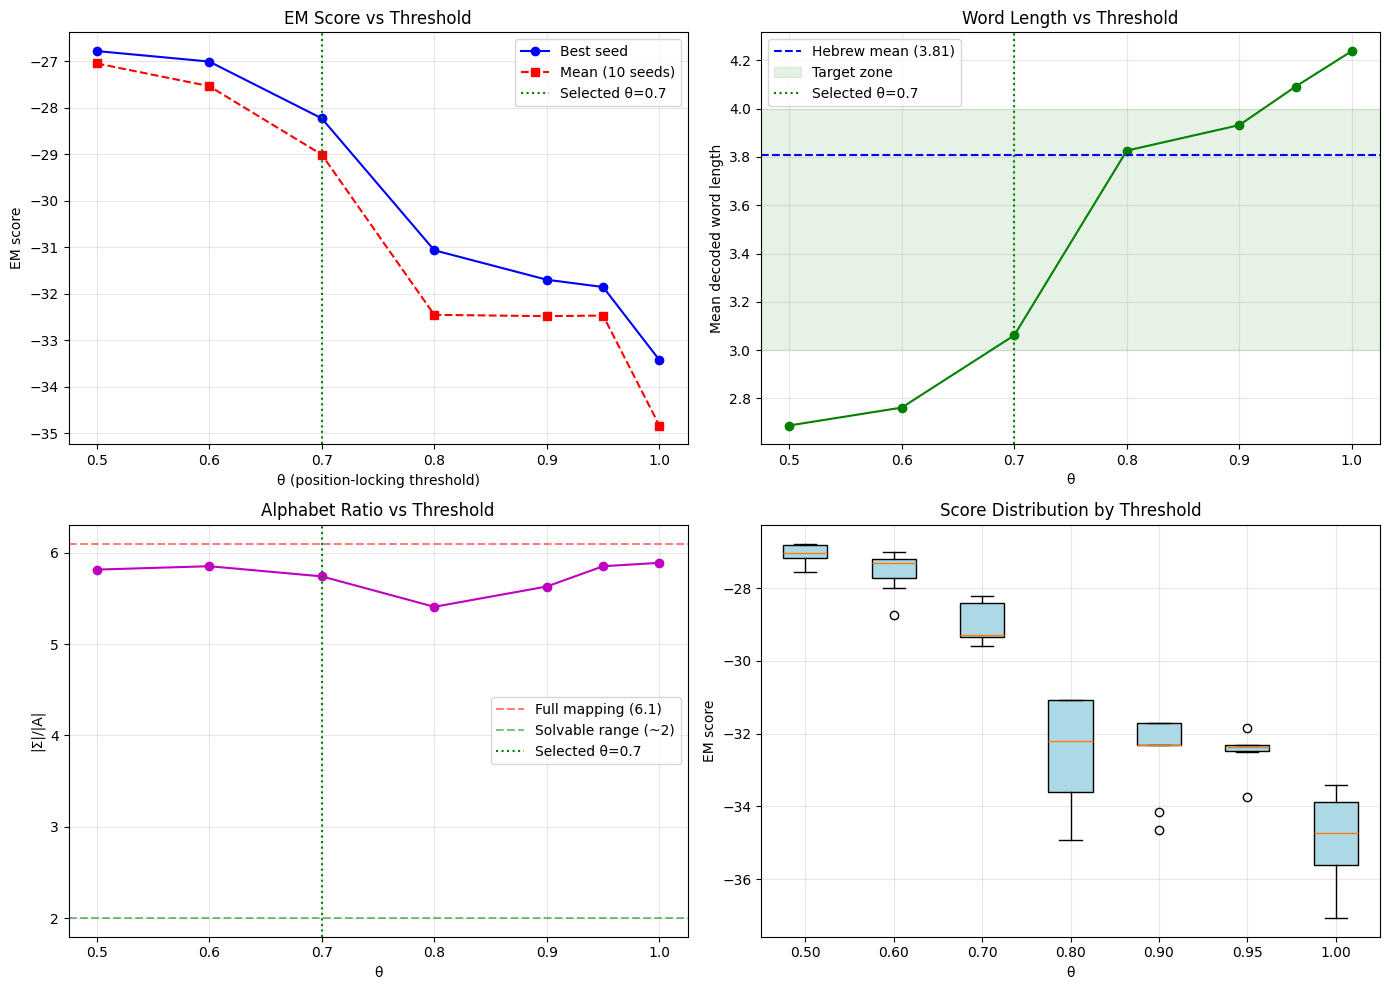

Saved: images/partial_null_sweep.png


In [8]:
# ── Cell 8: Visualizations ──────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Score vs θ
ax = axes[0, 0]
thetas_plot = []
scores_best = []
scores_mean = []
for theta in THETAS:
    results = sweep_results[theta]
    thetas_plot.append(theta)
    scores_best.append(max(r['score'] for r in results))
    scores_mean.append(np.mean([r['score'] for r in results]))
ax.plot(thetas_plot, scores_best, 'bo-', label='Best seed')
ax.plot(thetas_plot, scores_mean, 'rs--', label='Mean (10 seeds)')
ax.axvline(BEST_THETA, color='green', ls=':', label=f'Selected θ={BEST_THETA}')
ax.set_xlabel('θ (position-locking threshold)')
ax.set_ylabel('EM score')
ax.set_title('EM Score vs Threshold')
ax.legend()
ax.grid(True, alpha=0.3)

# 2. Mean decoded length vs θ
ax = axes[0, 1]
mean_lens = [theta_stats[t]['mean_len'] for t in THETAS]
ax.plot(THETAS, mean_lens, 'go-')
ax.axhline(3.81, color='blue', ls='--', label='Hebrew mean (3.81)')
ax.axhspan(3.0, 4.0, color='green', alpha=0.1, label='Target zone')
ax.axvline(BEST_THETA, color='green', ls=':', label=f'Selected θ={BEST_THETA}')
ax.set_xlabel('θ')
ax.set_ylabel('Mean decoded word length')
ax.set_title('Word Length vs Threshold')
ax.legend()
ax.grid(True, alpha=0.3)

# 3. |Σ|/|A| vs θ
ax = axes[1, 0]
ratios = [theta_stats[t]['ratio'] for t in THETAS]
ax.plot(THETAS, ratios, 'mo-')
ax.axhline(6.1, color='red', ls='--', alpha=0.5, label='Full mapping (6.1)')
ax.axhline(2.0, color='green', ls='--', alpha=0.5, label='Solvable range (~2)')
ax.axvline(BEST_THETA, color='green', ls=':', label=f'Selected θ={BEST_THETA}')
ax.set_xlabel('θ')
ax.set_ylabel('|Σ|/|A|')
ax.set_title('Alphabet Ratio vs Threshold')
ax.legend()
ax.grid(True, alpha=0.3)

# 4. Score distribution per θ (boxplot)
ax = axes[1, 1]
data_box = [[r['score'] for r in sweep_results[t]] for t in THETAS]
bp = ax.boxplot(data_box, labels=[f'{t:.2f}' for t in THETAS], patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
ax.set_xlabel('θ')
ax.set_ylabel('EM score')
ax.set_title('Score Distribution by Threshold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/partial_null_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/partial_null_sweep.png')

In [9]:
# ── Cell 9: Decoded samples ──────────────────────────────────────────

print(f'=== Sample decoded words (θ = {BEST_THETA:.2f}) ===')
print(f'{"Voynich word":25s} {"Content":20s} {"Decoded":15s}')
print('─' * 65)
for i in range(min(30, len(words))):
    v_str = ' '.join(words[i])
    c_str = ' '.join(content_words_best[i])
    d_str = ''.join(final_state.decode_word(content_words_best[i]))
    print(f'{v_str:25s} {c_str:20s} {d_str}')

# ── Comparison across θ values ──
print(f'\n=== Threshold comparison ===')
print(f'{"θ":>5s} {"NULLs":>6s} {"Σ/A":>6s} {"Mean len":>9s} {"Best score":>11s}')
print('─' * 45)
for theta in THETAS:
    best = max(sweep_results[theta], key=lambda r: r['score'])
    ts = theta_stats[theta]
    marker = ' ◄' if theta == BEST_THETA else ''
    print(f'{theta:5.2f} {len(ts["null_glyphs"]):6d} {ts["ratio"]:6.2f} '
          f'{ts["mean_len"]:9.2f} {best["score"]:11.4f}{marker}')

=== Sample decoded words (θ = 0.70) ===
Voynich word              Content              Decoded        
─────────────────────────────────────────────────────────────────
P2 A3 K1 A2 C2            A3 K1 C2             והה
A2 Q1 A3 B2               Q1 A3 B2             הוה
A3 C1                     A3                   ו
Aa Q2 A3 G1               Aa Q2 A3             יהו
L1 A1 B2                  A1 B2                יה
L1 A1 C1 A2               A1                   י
U5 C2 J1 C2               C2 J1 C2             הוה
A2                        A2                   א
Q1 A1 C1                  Q1 A1                הי
L1 A1 B2 B1 A2            A1 B2 B1             יהה
C2 A1 C1 A2               C2 A1                הי
U1 A3 C1                  A3                   ו
A1 C1 A2                  A1                   י
Q1 A3 F3                  Q1 A3 F3             הוה
K1 Q2 A3 G1               K1 Q2 A3             ההו
L1 A3 C1                  A3                   ו
Aa E1 C2                  Aa E

In [ ]:
# ── Cell 10: Export results ──────────────────────────────────────────

# Build sweep summary
sweep_summary = {}
for theta in THETAS:
    results = sweep_results[theta]
    best = max(results, key=lambda r: r['score'])
    ts = theta_stats[theta]
    sweep_summary[str(theta)] = {
        'n_null': len(ts['null_glyphs']),
        'n_content': len(ts['content_vocab']),
        'mean_len': round(ts['mean_len'], 2),
        'ratio_sigma_A': round(ts['ratio'], 2),
        'best_score': round(best['score'], 4),
        'mean_score': round(np.mean([r['score'] for r in results]), 4),
        'best_K_eff': best['K_eff'],
    }

results_json = {
    'metadata': {
        'model': 'Partial NULL (Model 14)',
        'description': 'Parameterized threshold for NULL classification; sweep over θ ∈ [0.5, 1.0]',
        'selected_theta': BEST_THETA,
        'n_null_glyphs': len(theta_stats[BEST_THETA]['null_glyphs']),
        'content_vocab': len(content_vocab_best),
        'ratio_sigma_A': round(theta_stats[BEST_THETA]['ratio'], 2),
        'mean_content_length': round(theta_stats[BEST_THETA]['mean_len'], 2),
        'mean_orig_length': round(np.mean([len(w) for w in words]), 2),
        'lm': 'LSTM 2-layer (embed=32, hidden=192)',
        'temperature': T_FIXED,
        'n_seeds_per_theta': N_SEEDS,
        'n_thetas': len(THETAS),
    },
    'sweep': sweep_summary,
    'scorecard': {
        'collapse_z': round(mean_z, 3),
        'ngram_percentile': round(ngram_pct, 1),
        'roots_found': len(roots_found),
        'roots_list': sorted(roots_found),
        'cardinality_ratio': round(card_ratio, 3),
        'K_eff': K_eff,
        'word_length_z': round(z_len, 2),
        'rhat_pct': round(pct_converged, 1),
        'verdicts': verdicts,
        'summary': f'{n_pass}+/{n_marg}±/{n_fail}−',
    },
    'best_em': {
        'score': round(BEST_EM['score'], 4),
        'seed': BEST_EM['seed'],
        'K_eff': BEST_EM['K_eff'],
    },
    'mcmc_best_score': round(global_best_score, 4),
    'val_loss': round(best_val_loss, 4),
}

with open('partial_null_resultados.json', 'w') as f:
    json.dump(results_json, f, indent=2, ensure_ascii=False)

print('Results saved to partial_null_results.json')
print(json.dumps(results_json, indent=2, ensure_ascii=False))

Results saved to partial_null_resultados.json
{
  "metadata": {
    "model": "Partial NULL (Model 14)",
    "description": "Parameterized threshold for NULL classification; sweep over θ ∈ [0.5, 1.0]",
    "selected_theta": 0.7,
    "n_null_glyphs": 38,
    "content_vocab": 155,
    "ratio_sigma_A": 5.74,
    "mean_content_length": 3.06,
    "mean_orig_length": 4.24,
    "lm": "LSTM 2-layer (embed=32, hidden=192)",
    "temperature": 2.0,
    "n_seeds_per_theta": 10,
    "n_thetas": 7
  },
  "sweep": {
    "0.5": {
      "n_null": 47,
      "n_content": 157,
      "mean_len": 2.69,
      "ratio_sigma_A": 5.81,
      "best_score": -26.7762,
      "mean_score": -27.0418,
      "best_K_eff": 27
    },
    "0.6": {
      "n_null": 43,
      "n_content": 158,
      "mean_len": 2.76,
      "ratio_sigma_A": 5.85,
      "best_score": -27.002,
      "mean_score": -27.5312,
      "best_K_eff": 27
    },
    "0.7": {
      "n_null": 38,
      "n_content": 155,
      "mean_len": 3.06,
      "ratio_

: 